In [1]:
print ('hello world')

hello world


In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report


In [4]:
df = pd.read_csv('heart_failure.csv')

In [5]:
df.shape

(299, 12)

In [6]:
df.isnull

<bound method DataFrame.isnull of      S no.   age  anaemia  creatinine phosphokinase  diabetes  \
0        1  75.0        0                       582         0   
1        2  55.0        0                      7861         0   
2        3  65.0        0                       146         0   
3        4  50.0        1                       111         0   
4        5  65.0        1                       160         1   
..     ...   ...      ...                       ...       ...   
294    295  62.0        0                        61         1   
295    296  55.0        0                      1820         0   
296    297  45.0        0                      2060         1   
297    298  45.0        0                      2413         0   
298    299  50.0        0                       196         0   

     ejection fraction  high bp  platelets  serum creatinine  sex  smoking  \
0                   20        1  265000.00               1.9    1        0   
1                   38       

In [8]:
df.isnull().sum()


S no.                       0
age                         0
anaemia                     0
creatinine phosphokinase    0
diabetes                    0
ejection fraction           0
high bp                     0
platelets                   0
serum creatinine            0
sex                         0
smoking                     0
death                       0
dtype: int64

In [10]:
df.describe()

,S no.,age,anaemia,creatinine phosphokinase,diabetes,ejection fraction,high bp,platelets,serum creatinine,sex,smoking,death
count,299.000000,299.000000,299.000000,299.000000,299.000000,299.000000,299.000000,299.000000,299.00000,299.000000,299.00000,299.00000
mean,150.000000,60.833893,0.431438,581.839465,0.418060,38.083612,0.351171,263358.029264,1.39388,0.648829,0.32107,0.32107
std,86.458082,11.894809,0.496107,970.287881,0.494067,11.834841,0.478136,97804.236869,1.03451,0.478136,0.46767,0.46767
min,1.000000,40.000000,0.000000,23.000000,0.000000,14.000000,0.000000,25100.000000,0.50000,0.000000,0.00000,0.00000
25%,75.500000,51.000000,0.000000,116.500000,0.000000,30.000000,0.000000,212500.000000,0.90000,0.000000,0.00000,0.00000
50%,150.000000,60.000000,0.000000,250.000000,0.000000,38.000000,0.000000,262000.000000,1.10000,1.000000,0.00000,0.00000
75%,224.500000,70.000000,1.000000,582.000000,1.000000,45.000000,1.000000,303500.000000,1.40000,1.000000,1.00000,1.00000
max,299.000000,95.000000,1.000000,7861.000000,1.000000,80.000000,1.000000,850000.000000,9.40000,1.000000,1.00000,1.00000


In [11]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 299 entries, 0 to 298
Data columns (total 12 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   S no.                     299 non-null    int64  
 1   age                       299 non-null    float64
 2   anaemia                   299 non-null    int64  
 3   creatinine phosphokinase  299 non-null    int64  
 4   diabetes                  299 non-null    int64  
 5   ejection fraction         299 non-null    int64  
 6   high bp                   299 non-null    int64  
 7   platelets                 299 non-null    float64
 8   serum creatinine          299 non-null    float64
 9   sex                       299 non-null    int64  
 10  smoking                   299 non-null    int64  
 11  death                     299 non-null    int64  
dtypes: float64(3), int64(9)
memory usage: 28.2 KB


In [ ]:
df.drop(columns=['S no.'], inplace=True)

C:\Users\abhin\AppData\Local\Temp\ipykernel_26864\2971975274.py:1: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(data=df, x='death', palette=['yellow', 'green'])


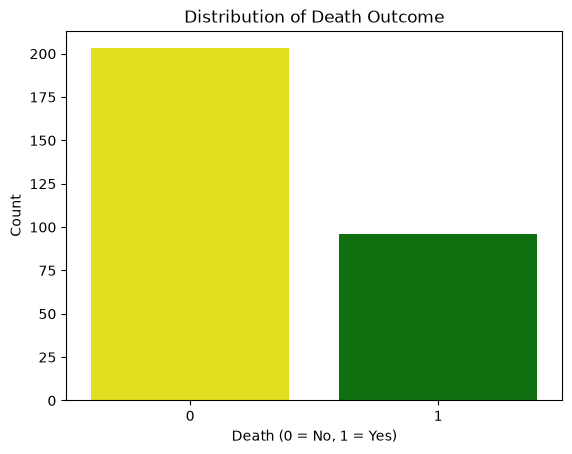

In [15]:
sns.countplot(data=df, x='death', palette=['yellow', 'green'])
plt.title('Distribution of Death Outcome')
plt.xlabel('Death (0 = No, 1 = Yes)')
plt.ylabel('Count')
plt.show()

In [16]:
x = df.drop('death', axis=1)
y = df['death']

xtrain, xtest, ytrain, ytest = train_test_split(x, y, test_size=0.2, random_state=42)

In [19]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()

xtrain_scaled = pd.DataFrame(
    scaler.fit_transform(xtrain),
    columns=xtrain.columns,
    index=xtrain.index
)

xtest_scaled = pd.DataFrame(
    scaler.transform(xtest),
    columns=xtest.columns,
    index=xtest.index
)

xtrain_scaled

,S no.,age,anaemia,creatinine phosphokinase,diabetes,ejection fraction,high bp,platelets,serum creatinine,sex,smoking
6,-1.674631,1.164202,1.139332,-0.350370,-0.826498,-2.000867,-0.736163,-1.439568,-0.188705,0.742932,-0.676252
183,0.364103,1.164202,-0.877707,-0.505933,-0.826498,-0.022672,1.358395,-0.408476,1.120602,0.742932,-0.676252
185,0.387139,-0.032819,1.139332,-0.500642,1.209925,-0.710740,-0.736163,1.345442,0.113442,0.742932,-0.676252
146,-0.062073,-0.756645,-0.877707,-0.471011,-0.826498,-0.710740,-0.736163,-0.472255,-0.692285,0.742932,1.478738
30,-1.398193,2.750989,-0.877707,0.005203,1.209925,-0.022672,1.358395,0.009892,0.445805,0.742932,-0.676252
...,...,...,...,...,...,...,...,...,...,...,...
188,0.421694,-0.032819,1.139332,-0.450904,1.209925,0.149345,1.358395,-0.652962,-0.390137,-1.346018,-0.676252
71,-0.925944,-0.255554,-0.877707,0.005203,1.209925,-0.280697,-0.736163,-1.492717,-0.490853,0.742932,1.478738
106,-0.522804,-0.506099,-0.877707,0.180873,-0.826498,0.579388,-0.736163,0.006086,-0.087989,0.742932,-0.676252
270,1.366192,-1.424765,-0.877707,0.005203,1.209925,-0.710740,1.358395,0.009892,0.214158,0.742932,1.478738


In [22]:
heart_model = LogisticRegression()
heart_model.fit(xtrain_scaled, ytrain)
y_pred = heart_model.predict(xtest_scaled)

In [23]:
print("Accuracy:", accuracy_score(ytest, y_pred))
print("Confusion Matrix:\n", confusion_matrix(ytest, y_pred))
print("Classification Report:\n", classification_report(ytest, y_pred))

Accuracy: 0.7833333333333333
Confusion Matrix:
 [[33  2]
 [11 14]]
Classification Report:
               precision    recall  f1-score   support

           0       0.75      0.94      0.84        35
           1       0.88      0.56      0.68        25

    accuracy                           0.78        60
   macro avg       0.81      0.75      0.76        60
weighted avg       0.80      0.78      0.77        60



In [24]:
import pickle
import joblib

joblib.dump(heart_model, 'heart_model.pkl')
joblib.dump(scaler, 'scaler.pkl')

['scaler.pkl']

In [27]:
from sklearn.tree import DecisionTreeClassifier

decision_tree_model = DecisionTreeClassifier(random_state=42)
decision_tree_model.fit(xtrain, ytrain)

y_pred_tree = decision_tree_model.predict(xtest)

print("Accuracy:", accuracy_score(ytest, y_pred_tree))
print("Confusion Matrix:\n", confusion_matrix(ytest, y_pred_tree))
print("Classification Report:\n", classification_report(ytest, y_pred_tree))

Accuracy: 0.65
Confusion Matrix:
 [[28  7]
 [14 11]]
Classification Report:
               precision    recall  f1-score   support

           0       0.67      0.80      0.73        35
           1       0.61      0.44      0.51        25

    accuracy                           0.65        60
   macro avg       0.64      0.62      0.62        60
weighted avg       0.64      0.65      0.64        60



In [29]:
from sklearn.ensemble import RandomForestClassifier

random_forest_model = RandomForestClassifier(random_state=42)
random_forest_model.fit(xtrain, ytrain)

y_pred_rf = random_forest_model.predict(xtest)

print("Accuracy:", accuracy_score(ytest, y_pred_rf))
print("Confusion Matrix:\n", confusion_matrix(ytest, y_pred_rf))
print("Classification Report:\n", classification_report(ytest, y_pred_rf))

Accuracy: 0.75
Confusion Matrix:
 [[33  2]
 [13 12]]
Classification Report:
               precision    recall  f1-score   support

           0       0.72      0.94      0.81        35
           1       0.86      0.48      0.62        25

    accuracy                           0.75        60
   macro avg       0.79      0.71      0.72        60
weighted avg       0.78      0.75      0.73        60



In [32]:
models_and_predictions = {
    "Logistic Regression": (heart_model, xtest_scaled),
    "Decision Tree": (decision_tree_model, xtest),
    "Random Forest": (random_forest_model, xtest),
}

for name, (model, test_data) in models_and_predictions.items():
    predictions = model.predict(test_data)

    print(f"\n{name}")
    print("Accuracy:", accuracy_score(ytest, predictions))
    print("Confusion Matrix:\n", confusion_matrix(ytest, predictions))
    print("Classification Report:\n", classification_report(ytest, predictions, zero_division=0))


Logistic Regression
Accuracy: 0.7833333333333333
Confusion Matrix:
 [[33  2]
 [11 14]]
Classification Report:
               precision    recall  f1-score   support

           0       0.75      0.94      0.84        35
           1       0.88      0.56      0.68        25

    accuracy                           0.78        60
   macro avg       0.81      0.75      0.76        60
weighted avg       0.80      0.78      0.77        60


Decision Tree
Accuracy: 0.65
Confusion Matrix:
 [[28  7]
 [14 11]]
Classification Report:
               precision    recall  f1-score   support

           0       0.67      0.80      0.73        35
           1       0.61      0.44      0.51        25

    accuracy                           0.65        60
   macro avg       0.64      0.62      0.62        60
weighted avg       0.64      0.65      0.64        60


Random Forest
Accuracy: 0.75
Confusion Matrix:
 [[33  2]
 [13 12]]
Classification Report:
               precision    recall  f1-score   supp